# Notebook 3: Strategic Learning, and the Three Mechanisms of Practice

Berman's claim is that a legal principle's *weight* is conferred by **practice** --
by what officials actually do with the principle over time. But "practice" is not
one definite thing. This notebook builds a **third** model of practice and then
sets all three side by side.

The three candidate mechanisms, each of which produces one weight per principle:

| Mechanism | Notebook | Where the weight comes from |
|---|---|---|
| **Uptake** | NB1 (`LegalSystem`) | how often a principle is invoked, off fixed methodology habits |
| **Reliance** | NB2 (`RelianceSystem`) | victories in embedded conflicts, amplified by reliance |
| **Strategic** | NB3 (`StrategicSystem`) | what judges *learn* to lean on when they optimise |

In the strategic model, judges are **reinforcement-learning agents**. Each judge
decides which principles to invoke in a case; the bench shares one *weight* on each
principle; and the judges adjust both to a reward (reaching a clear, agreed
verdict, without throwing in everything). The weight that the bench settles on is
read out as this mechanism's emergent weight vector.

### What this notebook establishes
1. A **sound, reproducible** reinforcement-learning model whose learned object is a
   genuine weighted-sum weight -- it enters the judges' force, and the reward moves
   it. (The original paper's version had neither property; see the setup notes.)
2. That this strategic weight **converges**, is **reproducible** bit-for-bit, and
   has a characterisable structure -- but that the structure is **sensitive to how
   the model is set up**, which is itself a finding.
3. That the strategic weights still satisfy **R1-R4**, on the *same* held-out test
   as NB1 and NB2.
4. The three-way comparison: **which weight structure practice produces depends on
   the mechanism**, yet all three satisfy what Berman requires.

### What this notebook does NOT claim
- It does **not** claim optimising judges are *Berman's* mechanism. Strategic
  learning is the **least Bermanian** of the three -- a robustness probe, not an
  interpretation. Reliance (NB2) is closest to Berman; uptake (NB1) is a
  simplification.
- It does **not** grade the weights pass/fail on how *gradated* they are. Berman
  permits equal weights, so gradation (D1) is reported descriptively only.
- It does **not** revive the old "some mechanisms fail" framing, the +19.1% Hart
  bar, or Hart tiers read off the weights under test. The honest claim is
  *structure is mechanism-dependent while R1-R4 hold under all three*.

## Setup

On Colab this mounts your Google Drive and works inside the project folder, so the
shared core, the data, and the figures live in one place and persist after the
runtime resets. Run locally, it just uses the current folder. The next cell writes
the shared core `berman_core.py`; everything after imports from it. The strategic
model needs PyTorch, which Colab has pre-installed.

In [1]:
import os
# The project folder on Google Drive (edit if you move the project):
PROJECT = '/content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06'
try:
    from google.colab import drive            # on Colab: mount Drive and work in the project folder
    drive.mount('/content/drive')
    os.makedirs(PROJECT, exist_ok=True); os.chdir(PROJECT)
    print('Colab: mounted Drive, working in', os.getcwd())
except ImportError:
    print('Local: working in', os.getcwd())   # already in the project folder

Mounted at /content/drive
Colab: mounted Drive, working in /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06


In [2]:
%%writefile berman_core.py
"""
berman_core.py — shared, corrected core for the Berman Modeling rebuild (2026-06).

ONE source of truth for the SAW model, principle sets, Hart baselines, a *seeded*
bootstrap, the activation generators, the weight-tolerance (critical-sigma)
machinery, and the redesigned evaluation criteria. Every notebook %%writefile's
this file and `from berman_core import *`, so a fix here propagates everywhere
(ends the verbatim-copy drift of the old notebooks).

Design decisions baked in (vs. the old code):
  * Determinacy convention is strict |F| > tau, matching the manuscript.
  * RNG is always explicit (np.random.default_rng(seed)); bootstrap is seeded
    and vectorized, so every CI is reproducible.
  * One determinacy cutoff (DEFAULT_TAU) everywhere — no 0.05-here-0.2-there.
  * Corrected category map: federalism is STRUCTURAL, not moral.
  * Criteria are split into REQUIREMENTS (R1-R4, pass/fail, derived from what
    Berman actually claims) and DESCRIPTIVE measures (D1-D2, reported, never used
    to fail the theory). See CONCEPTUAL_AUDIT_vs_Berman.md.
"""
from __future__ import annotations

from dataclasses import dataclass
from typing import Dict, List, Optional, Callable, Tuple

import numpy as np

__all__ = [
    "DEFAULT_TAU", "Principle", "NAMED_PRINCIPLES", "CATEGORY_INDEX",
    "make_weights", "named_weight_vector", "category_of",
    "net_force", "is_determinate", "determinacy_rate",
    "random_activations", "category_correlated_activations", "fully_correlated_activations",
    "bootstrap_ci", "critical_sigma", "CRITICAL_SIGMA_CEIL",
    "hart_hierarchical_determinate", "hart_consensus_determinate", "hart_advantage",
    "hart_validation_status",
    "nonlexicality_score", "ordinalize", "saw_verdict", "lexicographic_verdict",
    "weight_cv", "n_survivors", "cluster_gap",
    "METHODOLOGIES", "methodology_tendencies", "LegalSystem",
    "gmm_bimodal", "bimodality_coefficient",
    "RelianceSystem", "weight_entropy", "gini", "n_bins_occupied",
    "set_determinism", "StrategicSystem",
]

# ---------------------------------------------------------------------------
# Determinacy convention
# ---------------------------------------------------------------------------
DEFAULT_TAU: float = 0.20  # a case is determinate when |F| > tau (strict)


# ---------------------------------------------------------------------------
# Principles and categories  (federalism corrected to 'structural')
# ---------------------------------------------------------------------------
@dataclass
class Principle:
    name: str
    weight: float
    category: str = "structural"  # one of: 'textual', 'structural', 'moral'

    def __post_init__(self) -> None:
        assert 0.0 <= self.weight <= 1.0, f"weight out of [0,1]: {self.weight}"
        assert self.category in ("textual", "structural", "moral"), self.category


# The baseline 9-principle set. Order is fixed; categories are the corrected map.
NAMED_PRINCIPLES: List[Tuple[str, str]] = [
    ("text",       "textual"),
    ("original",   "textual"),
    ("precedent",  "structural"),
    ("structure",  "structural"),
    ("federalism", "structural"),   # <-- was grouped with 'moral' in the old code (bug)
    ("dignity",    "moral"),
    ("equality",   "moral"),
    ("liberty",    "moral"),
    ("welfare",    "moral"),
]

CATEGORY_INDEX: Dict[str, List[int]] = {
    cat: [i for i, (_, c) in enumerate(NAMED_PRINCIPLES) if c == cat]
    for cat in ("textual", "structural", "moral")
}


def category_of(i: int) -> str:
    return NAMED_PRINCIPLES[i][1]


# ---------------------------------------------------------------------------
# Weight generators
# ---------------------------------------------------------------------------
def make_weights(n: int, distribution: str, seed: int) -> np.ndarray:
    """Generate n weights. 'uniform' ~U(.60,.70); 'moderate' ~U(.50,.80);
    'high' ~U(.30,.95). Berman's weights are 'rough' (slight..nearly conclusive)."""
    rng = np.random.default_rng(seed)
    if distribution == "uniform":
        return rng.uniform(0.60, 0.70, n)
    if distribution == "moderate":
        return rng.uniform(0.50, 0.80, n)
    if distribution == "high":
        return rng.uniform(0.30, 0.95, n)
    raise ValueError(f"unknown distribution: {distribution}")


def named_weight_vector(distribution: str = "moderate", seed: int = 0) -> np.ndarray:
    """Weights for the 9 NAMED_PRINCIPLES under a given distribution."""
    return make_weights(len(NAMED_PRINCIPLES), distribution, seed)


# ---------------------------------------------------------------------------
# SAW model (nonlexical aggregation)
# ---------------------------------------------------------------------------
def net_force(weights: np.ndarray, activations: np.ndarray) -> np.ndarray:
    """F = sum_i w_i * a_i. Vectorized over a (..., n) activation array."""
    weights = np.asarray(weights, float)
    activations = np.asarray(activations, float)
    return np.sum(weights * activations, axis=-1)


def is_determinate(weights, activations, tau: float = DEFAULT_TAU):
    return np.abs(net_force(weights, activations)) > tau


def determinacy_rate(weights, activation_matrix, tau: float = DEFAULT_TAU) -> float:
    return float(np.mean(is_determinate(weights, activation_matrix, tau)))


# ---------------------------------------------------------------------------
# Activation generators (the conservative independent baseline + realistic structure)
# ---------------------------------------------------------------------------
def random_activations(n_cases: int, n_principles: int, rng: np.random.Generator) -> np.ndarray:
    """Independent activations ~ U(-1, 1). The conservative baseline."""
    return rng.uniform(-1.0, 1.0, size=(n_cases, n_principles))


def category_correlated_activations(n_cases: int, rng: np.random.Generator,
                                    rho: float = 0.7) -> np.ndarray:
    """Activations for the 9 NAMED_PRINCIPLES where principles in the same
    category share a common latent factor (textual together, structural together,
    moral together)."""
    n_p = len(NAMED_PRINCIPLES)
    a = np.empty((n_cases, n_p))
    for cat, idx in CATEGORY_INDEX.items():
        factor = rng.uniform(-1.0, 1.0, size=(n_cases, 1))
        idio = rng.uniform(-1.0, 1.0, size=(n_cases, len(idx)))
        a[:, idx] = np.clip(rho * factor + (1 - rho) * idio, -1.0, 1.0)
    return a


def fully_correlated_activations(n_cases: int, n_principles: int,
                                 rng: np.random.Generator, rho: float = 0.7) -> np.ndarray:
    """All principles share one latent factor."""
    factor = rng.uniform(-1.0, 1.0, size=(n_cases, 1))
    idio = rng.uniform(-1.0, 1.0, size=(n_cases, n_principles))
    return np.clip(rho * factor + (1 - rho) * idio, -1.0, 1.0)


# ---------------------------------------------------------------------------
# Bootstrap — SEEDED and vectorized (every CI is reproducible)
# ---------------------------------------------------------------------------
def bootstrap_ci(values, n_boot: int = 2000, ci: int = 95, seed: int = 0):
    """Return (mean, lo, hi) for a percentile bootstrap CI on the mean."""
    rng = np.random.default_rng(seed)
    arr = np.asarray(values, dtype=float)
    if arr.size == 0:
        return (float("nan"),) * 3
    means = rng.choice(arr, size=(n_boot, arr.size), replace=True).mean(axis=1)
    lo = float(np.percentile(means, (100 - ci) / 2))
    hi = float(np.percentile(means, 100 - (100 - ci) / 2))
    return float(arr.mean()), lo, hi


# ---------------------------------------------------------------------------
# Weight-uncertainty tolerance: critical sigma  (R2 — "rough weights suffice")
# ---------------------------------------------------------------------------
CRITICAL_SIGMA_CEIL = 1.0  # grid maximum; a returned value == this is right-censored


def critical_sigma(weights: np.ndarray, activation_matrix: np.ndarray,
                   tau: float = DEFAULT_TAU, accuracy: float = 0.80,
                   robust_thresh: float = 0.90, n_mc: int = 64, seed: int = 0,
                   sigma_grid: Optional[np.ndarray] = None) -> float:
    """Smallest weight-noise sigma at which fewer than `accuracy` of cases remain
    individually robust.

    Two-level definition: add N(0, sigma^2) to each weight (clipped to [0,1]); a
    *case* is robust at sigma if it keeps its unperturbed signed VERDICT
    (determinate-for / determinate-against / indeterminate) on at least
    `robust_thresh` of MC draws; sigma* is the smallest sigma at which the
    fraction of robust cases falls below `accuracy`.

    Verdict-stability (not just determinate/indeterminate class) so that a noise
    level that flips a determinate-for case to determinate-against counts as
    instability. The grid runs to CRITICAL_SIGMA_CEIL; a returned value equal to
    the ceiling is right-censored (true tolerance is >= ceiling) -- callers
    should flag these rather than average them as if measured.
    """
    rng = np.random.default_rng(seed)
    w = np.asarray(weights, float)
    A = np.asarray(activation_matrix, float)
    n_p = w.size
    if sigma_grid is None:
        sigma_grid = np.linspace(0.0, CRITICAL_SIGMA_CEIL, 51)

    true_F = A @ w
    true_v = np.sign(true_F); true_v[np.abs(true_F) <= tau] = 0    # (cases,) verdict
    noise = rng.standard_normal((n_mc, A.shape[0], n_p))          # (mc, cases, p)

    prev_sigma, prev_surv = 0.0, 1.0
    for sigma in sigma_grid:
        if sigma == 0:
            prev_sigma, prev_surv = 0.0, 1.0
            continue
        w_noisy = np.clip(w[None, None, :] + sigma * noise, 0.0, 1.0)
        F = np.einsum("mcp,cp->mc", w_noisy, A)                   # (mc, cases)
        v = np.sign(F); v[np.abs(F) <= tau] = 0
        agree_frac = np.mean(v == true_v[None, :], axis=0)        # per case
        survival = float(np.mean(agree_frac >= robust_thresh))
        if survival < accuracy:
            frac = (accuracy - prev_surv) / (survival - prev_surv)
            return float(prev_sigma + frac * (sigma - prev_sigma))
        prev_sigma, prev_surv = sigma, survival
    return float(sigma_grid[-1])  # right-censored at the ceiling


# ---------------------------------------------------------------------------
# Hart baselines  (R4 — "more law than Hart", reported as a margin/curve)
# ---------------------------------------------------------------------------
def hart_consensus_determinate(activations, frac: float = 0.6,
                               act_cut: float = 0.1) -> np.ndarray:
    """Consensus Hart (the faithful operationalization of Hart-as-validation):
    a case is determinate only when the share of *active* principles pointing the
    same direction exceeds `frac`. Hart requires agreement; below `frac` the law
    'runs out'."""
    A = np.atleast_2d(np.asarray(activations, float))
    pos = np.sum(A > act_cut, axis=1)
    neg = np.sum(A < -act_cut, axis=1)
    active = pos + neg
    with np.errstate(invalid="ignore", divide="ignore"):
        share = np.maximum(pos, neg) / np.where(active == 0, 1, active)
    return (active > 0) & (share > frac)


def hart_hierarchical_determinate(weights, activations, tier_of: np.ndarray,
                                  frac: float = 0.6, act_cut: float = 0.1,
                                  tau: float = DEFAULT_TAU) -> np.ndarray:
    """Charitable *lexical-priority* Hart: principles sit in priority tiers
    (0 = top). For each case, the highest-priority tier that has ANY active
    principle is DISPOSITIVE: that tier decides iff its active principles reach
    consensus (>= `frac` agree in sign); otherwise the law runs out. Lower tiers
    are NOT consulted once a higher tier is reached — that is the lexical priority
    Berman's nonlexical model is contrasted against, and it is what stops Hart
    from finding law in nearly every case via tier escape-hatches.
    """
    A = np.atleast_2d(np.asarray(activations, float))
    tier_of = np.asarray(tier_of, int)
    out = np.zeros(A.shape[0], dtype=bool)
    reached = np.zeros(A.shape[0], dtype=bool)  # a dispositive tier has been reached
    for t in np.unique(tier_of):
        idx = np.where(tier_of == t)[0]
        sub = A[:, idx]
        pos = np.sum(sub > act_cut, axis=1)
        neg = np.sum(sub < -act_cut, axis=1)
        active = pos + neg
        this_tier = (active > 0) & (~reached)        # cases first resolved at this tier
        with np.errstate(invalid="ignore", divide="ignore"):
            share = np.maximum(pos, neg) / np.where(active == 0, 1, active)
        out |= this_tier & (share > frac)             # decided iff consensus here (strict, matches consensus Hart)
        reached |= this_tier                           # dispositive; no escape downward
    return out


def hart_validation_status(activations, k: int = 2, act_cut: float = 0.5) -> np.ndarray:
    """Naive validation foil used to make Berman's 'no contradiction' point.

    A direction counts as independently 'validated' when at least `k` principles
    are strongly activated (|a| > act_cut) in that direction. Returns one integer
    code per case:
        0 = gap          (neither direction validated -> the law runs out)
        1 = for          (only the positive direction validated)
        2 = against      (only the negative direction validated)
        3 = contradiction(both directions validated -> q and not-q are both law)

    The point: code 3 is possible for a validation model, but impossible for
    Berman's aggregation, because a single net force has a single sign. So the sum
    never returns code 3.
    """
    A = np.atleast_2d(np.asarray(activations, float))
    pos = np.sum(A > act_cut, axis=1) >= k
    neg = np.sum(A < -act_cut, axis=1) >= k
    code = np.zeros(A.shape[0], dtype=int)
    code[pos & ~neg] = 1
    code[neg & ~pos] = 2
    code[pos & neg] = 3
    return code


def hart_advantage(weights, activation_matrix, tier_of, frac: float = 0.6,
                   tau: float = DEFAULT_TAU) -> float:
    """Berman determinacy rate minus hierarchical-Hart determinacy rate (a margin,
    not a pass/fail)."""
    berman = determinacy_rate(weights, activation_matrix, tau)
    hart = float(np.mean(hart_hierarchical_determinate(
        weights, activation_matrix, tier_of, frac=frac, tau=tau)))
    return berman - hart


# ---------------------------------------------------------------------------
# R3 — nonlexicality.  Does determination track activation MAGNITUDES (and many
# principles jointly), as Berman requires, rather than just signs/ranks (lexical)?
# ---------------------------------------------------------------------------
def ordinalize(weights: np.ndarray) -> np.ndarray:
    """Replace weights by rank-based pseudo-weights (1..n)/n — discards cardinal info."""
    order = np.argsort(np.argsort(weights))  # ranks 0..n-1
    return (order + 1) / len(weights)


# Verdict functions return an integer verdict per case: +1 / -1 (determinate for
# / against) or 0 (indeterminate). These are the inputs to the R3 nonlexicality
# probe and are reused by the aggregation-function suite.
def saw_verdict(weights, activation_matrix, tau: float = DEFAULT_TAU) -> np.ndarray:
    """Nonlexical: verdict from the *magnitude-weighted sum* of all principles."""
    F = np.asarray(activation_matrix, float) @ np.asarray(weights, float)
    v = np.sign(F)
    v[np.abs(F) <= tau] = 0
    return v.astype(int)


def lexicographic_verdict(weights, activation_matrix, act_cut: float = 0.05) -> np.ndarray:
    """Lexical: verdict from the SIGN of the single highest-weight active
    principle (Raz exclusionary-reasons style). This is the mode Berman's theory
    is defined against — included only as the lexical foil for the R3 probe."""
    w = np.asarray(weights, float)
    A = np.atleast_2d(np.asarray(activation_matrix, float))
    order = np.argsort(-w)  # highest weight first
    out = np.zeros(A.shape[0], dtype=int)
    decided = np.zeros(A.shape[0], dtype=bool)
    for j in order:
        active = (np.abs(A[:, j]) > act_cut) & (~decided)
        out[active] = np.sign(A[active, j]).astype(int)
        decided |= active
    return out


def nonlexicality_score(verdict_fn: Callable[[np.ndarray], np.ndarray],
                        activation_matrix: np.ndarray,
                        seed: int = 0, n_mc: int = 32, jitter: float = 0.20) -> float:
    """R3 probe. Fraction of cases whose VERDICT changes under a magnitude-only
    perturbation of activations that preserves every activation's sign AND the
    within-case rank order of |activation|.

    A lexical rule (decides on the top-ranked active principle) is invariant to
    such perturbations -> score ~ 0. A genuinely nonlexical, magnitude-aggregating
    rule (SAW) is sensitive -> score > 0. `verdict_fn(A)` maps an (n,9) activation
    matrix to an integer verdict array in {-1,0,+1}.
    """
    rng = np.random.default_rng(seed)
    A = np.asarray(activation_matrix, float)
    base = verdict_fn(A)
    rank = np.argsort(np.argsort(np.abs(A), axis=1), axis=1)  # rank of |a| within row
    n_p = A.shape[1]
    changed = np.zeros(A.shape[0])
    for _ in range(n_mc):
        mag = np.clip(np.abs(A) * (1 + rng.uniform(-jitter, jitter, A.shape)), 0, 1)
        sorted_mag = np.sort(mag, axis=1)
        # Strictly-increasing epsilon breaks ties created when two magnitudes both
        # clip to 1.0; without this, re-placing tied values by index can silently
        # change the rank order (and thus the decision of a lexical rule). This
        # guarantees |A2| keeps the ORIGINAL within-row rank order exactly.
        sorted_mag = sorted_mag + 1e-9 * np.arange(n_p)
        A2 = np.sign(A) * np.take_along_axis(sorted_mag, rank, axis=1)
        changed += (verdict_fn(A2) != base)
    return float(np.mean(changed / n_mc))


# ---------------------------------------------------------------------------
# Descriptive weight statistics (D1 gradation, and emergence diagnostics)
# ---------------------------------------------------------------------------
def weight_cv(weights: np.ndarray) -> float:
    w = np.asarray(weights, float)
    m = w.mean()
    return float(w.std() / m) if m > 0 else 0.0


def n_survivors(weights: np.ndarray, cutoff: float = 0.05) -> int:
    return int(np.sum(np.asarray(weights, float) > cutoff))


def cluster_gap(weights: np.ndarray) -> float:
    """Gap between the two k-means clusters of weights (bimodality diagnostic)."""
    w = np.sort(np.asarray(weights, float))
    if w.size < 2:
        return 0.0
    best = None
    for k in range(1, w.size):
        lo, hi = w[:k], w[k:]
        gap = hi.mean() - lo.mean()
        if best is None or gap > best:
            best = gap
    return float(best)


# ===========================================================================
# Agent-based model of weight emergence (Notebook 1)
# ===========================================================================
# A bench of judges, each carrying an interpretive methodology that sets how
# often it invokes each principle. A principle's emergent "uptake share" is how
# often the bench takes it up across decisions. This is a deliberately simple
# model of Berman's "taking-up" (JESP p. 302); it is NOT his full account of
# weight, which is conferred by reliance and by winning conflicts (pp. 322, 324)
# and is taken up in Notebook 1c. The emergent quantity here is called "uptake
# share," never "weight in Berman's sense."

METHODOLOGIES = ("textualist", "purposivist", "pragmatist", "originalist")

# For each methodology, the principles it tends to invoke often ('high') or
# rarely ('low'); anything unlisted is 'medium'. Names refer to NAMED_PRINCIPLES.
_METH_SETS = {
    "textualist":  {"high": {"text", "original"},
                    "low":  {"dignity", "equality", "liberty", "welfare"}},
    "purposivist": {"high": {"dignity", "equality", "liberty"},
                    "low":  {"text", "original", "federalism"}},
    "pragmatist":  {"high": {"welfare", "precedent"},
                    "low":  {"dignity", "equality", "original"}},
    "originalist": {"high": {"original", "text", "federalism"},
                    "low":  {"dignity", "equality", "liberty", "welfare"}},
}

# Invocation-probability ranges (high, medium, low) by how specialized the
# methodologies are. 'wide' = strong specialization (headline); 'narrow' = nearly
# homogeneous (used to show heterogeneity is necessary for the split).
_SPREAD_RANGES = {
    "wide":   ((0.85, 0.95), (0.35, 0.65), (0.02, 0.08)),
    "medium": ((0.70, 0.80), (0.40, 0.60), (0.15, 0.25)),
    "narrow": ((0.60, 0.70), (0.42, 0.58), (0.30, 0.40)),
}


def methodology_tendencies(methodology: str, spread: str, rng) -> np.ndarray:
    """A 9-vector of per-principle invocation probabilities for one judge of a
    given methodology, drawn from the high/medium/low ranges set by `spread`."""
    hi, med, lo = _SPREAD_RANGES[spread]
    sets = _METH_SETS[methodology]
    t = np.empty(len(NAMED_PRINCIPLES))
    for i, (name, _) in enumerate(NAMED_PRINCIPLES):
        rng_range = hi if name in sets["high"] else (lo if name in sets["low"] else med)
        t[i] = rng.uniform(*rng_range)
    return t


class LegalSystem:
    """A bench of judges whose case-by-case invocations produce emergent
    principle uptake-shares.

    `turnover` selects how judges are replaced over time:
      'static'      no replacement (the headline emergence must hold here);
      'fitness'     replace the least decisive 20% with mutated copies of the
                    most decisive 20% (the old, suspect, non-Bermanian rule);
      'appointment' replace a random 20%, reseated from the methodology pool;
      'noise'       replace a random 20% with mutated copies of random judges.
    The point of the four regimes is to show the emergent structure does NOT
    depend on the turnover rule.
    """

    def __init__(self, n_agents=100, methodology_mix=None, spread="wide",
                 use_threshold=True, threshold_pct=50, turnover="static",
                 boost_cut=0.3, learn_from_system=0.15, seed=0):
        # One master seed -> five independent streams. No global np.random.
        ss = np.random.SeedSequence(seed)
        (self._rng_agents, self._rng_panels, self._rng_cases,
         self._rng_dec, self._rng_rep) = (np.random.default_rng(s) for s in ss.spawn(5))
        self.n_agents = n_agents
        self.spread = spread
        self.use_threshold = use_threshold
        self.threshold_pct = threshold_pct
        self.turnover = turnover
        self.boost_cut = boost_cut
        self.learn_from_system = learn_from_system
        self.n_p = len(NAMED_PRINCIPLES)

        # Assign methodologies exactly (round-robin or a given mix), then permute
        # the arrangement with the seeded generator (never np.random.shuffle).
        if methodology_mix is None:
            base = [METHODOLOGIES[i % 4] for i in range(n_agents)]
        else:
            base = []
            for m, frac in methodology_mix.items():
                base += [m] * int(round(frac * n_agents))
            base = (base + [METHODOLOGIES[0]] * n_agents)[:n_agents]
        self.methodology = list(self._rng_agents.permutation(base))
        self.tendencies = np.array([methodology_tendencies(m, spread, self._rng_agents)
                                    for m in self.methodology])     # (n_agents, 9)
        self.system_weights = np.full(self.n_p, 0.5)                # uniform init
        self.raw_uptake = np.full(self.n_p, 0.5)                    # pre-threshold share
        self.success = np.zeros(n_agents)
        self.decisions = np.zeros(n_agents)
        self.trajectory = []

    def _recompute_weights(self, counts, total):
        raw = counts / max(total, 1)
        raw = raw / max(raw.max(), 1e-12)                           # normalize to max
        self.raw_uptake = raw.copy()                               # the pre-threshold vector
        w = raw.copy()
        if self.use_threshold:                                     # zero the bottom percentile
            cut = np.percentile(w, self.threshold_pct)
            w = np.where(w < cut, 0.0, w)
            if w.max() > 0:
                w = w / w.max()
        self.system_weights = w

    def _replace(self, idx_out, idx_template):
        for o, t in zip(idx_out, idx_template):
            self.methodology[o] = self.methodology[t]
            self.tendencies[o] = np.clip(self.tendencies[t] + self._rng_rep.normal(0, 0.03, self.n_p),
                                         0.02, 0.98)
            self.success[o] = 0.0
            self.decisions[o] = 0.0

    def _turnover_step(self):
        k = max(1, int(0.2 * self.n_agents))
        if self.turnover == "static":
            return
        if self.turnover == "fitness":
            # eligible only with >= 5 decisions, so 1-2-case luck cannot rank an agent
            rate = np.where(self.decisions >= 5, self.success / np.maximum(self.decisions, 1), -1.0)
            order = np.argsort(rate)
            self._replace(order[:k], order[-k:])                   # bottom k <- top k
        elif self.turnover == "appointment":
            for o in self._rng_rep.choice(self.n_agents, k, replace=False):
                m = METHODOLOGIES[int(self._rng_rep.integers(4))]
                self.methodology[o] = m
                self.tendencies[o] = methodology_tendencies(m, self.spread, self._rng_rep)
                self.success[o] = 0.0
                self.decisions[o] = 0.0
        elif self.turnover == "noise":
            self._replace(self._rng_rep.choice(self.n_agents, k, replace=False),
                          self._rng_rep.choice(self.n_agents, k, replace=False))

    def simulate(self, n_cases=2000, panel_size=9, update_every=100, selection_every=500):
        counts = np.zeros(self.n_p)
        total = 0
        A = self._rng_cases.uniform(-1, 1, size=(n_cases, self.n_p))           # case stream up front
        panels = np.array([self._rng_panels.choice(self.n_agents, panel_size, replace=False)
                           for _ in range(n_cases)])
        self.trajectory = []
        for c in range(n_cases):
            a = A[c]
            panel = panels[c]
            tend = self.tendencies[panel]                                      # (panel, 9)
            prob = 0.85 * tend + self.learn_from_system * self.system_weights[None, :]
            boost = np.abs(a) > self.boost_cut                                 # strong activations invoked more
            prob = np.where(boost[None, :], np.minimum(prob * 1.15, 0.99), prob)
            invoked = self._rng_dec.uniform(size=(panel_size, self.n_p)) < prob
            counts += invoked.sum(axis=0)
            total += int(invoked.sum())
            forces = (invoked * self.system_weights[None, :] * a[None, :]).sum(axis=1)  # SAW per judge
            med = np.median(np.abs(forces))
            self.success[panel] += (np.abs(forces) >= med)                     # fitness bookkeeping
            self.decisions[panel] += 1
            if (c + 1) % update_every == 0:
                self._recompute_weights(counts, total)
                # record the smooth pre-threshold uptake for convergence/trajectory
                self.trajectory.append((c + 1, self.raw_uptake.copy()))
            if (c + 1) % selection_every == 0:
                self._turnover_step()
        self._recompute_weights(counts, total)
        return self.system_weights


def gmm_bimodal(values, seed=0, dbic_thresh=10.0):
    """Two-vs-one Gaussian-mixture BIC test for bimodality. Returns
    (dbic, separated, is_bimodal): dbic = BIC(1) - BIC(2) (larger favors two
    components); `separated` requires the two means be at least one larger-
    component SD apart (rejects two overlapping Gaussians). Deterministic."""
    from sklearn.mixture import GaussianMixture
    x = np.asarray(values, float).reshape(-1, 1)
    if len(np.unique(np.round(x, 6))) < 2:
        return 0.0, False, False
    g1 = GaussianMixture(1, random_state=seed, n_init=5).fit(x)
    g2 = GaussianMixture(2, random_state=seed, n_init=5).fit(x)
    dbic = float(g1.bic(x) - g2.bic(x))
    means = g2.means_.ravel()
    sds = np.sqrt(g2.covariances_.ravel())
    separated = bool(abs(means[0] - means[1]) > sds.max())
    return dbic, separated, bool(dbic > dbic_thresh and separated)


def bimodality_coefficient(values):
    """Sarle's bimodality coefficient. > 0.555 suggests bimodality. Underpowered
    for very small n, so use it on pooled data, not a single 9-vector."""
    from scipy import stats as _st
    x = np.asarray(values, float)
    n = x.size
    if n < 4:
        return float("nan")
    g = _st.skew(x); k = _st.kurtosis(x, fisher=True)
    return float((g**2 + 1) / (k + 3 * (n - 1)**2 / ((n - 2) * (n - 3))))


# ===========================================================================
# Reliance / by-battle weight conferral (Notebook 2)
# ===========================================================================
# Berman's conferred weight (JESP pp. 322, 324): a principle gains weight by
# winning CONTESTED, DISPOSITIVE battles, amplified by how much the deciding
# precedent is later RELIED UPON (cited), decayed gradually, and removed when a
# precedent is OVERRULED. Battles are decided by a FIXED exogenous "pressure"
# structure (the practice), NOT by the conferred weight being built: making it
# literally circular ("weight made so by battle") produces runaway lock-in, so
# the decision and the read-out are decoupled. There is NO weight floor -- that
# is what made the old "precedent stock" collapse to uniform weights.

def weight_entropy(w):
    """Shannon entropy of a normalized weight vector (higher = more spread)."""
    w = np.asarray(w, float); s = w.sum()
    if s <= 0:
        return 0.0
    p = w / s; p = p[p > 0]
    return float(-(p * np.log(p)).sum())


def gini(w):
    """Gini coefficient of a weight vector (0 = equal, ->1 = concentrated)."""
    w = np.sort(np.asarray(w, float)); n = len(w)
    if w.sum() == 0:
        return 0.0
    return float((2 * np.arange(1, n + 1) - n - 1).dot(w) / (n * w.sum()))


def n_bins_occupied(w, edges=(0.2, 0.4, 0.6, 0.8)):
    """How many of Berman's ~5 rough weight bands a weight vector occupies."""
    return int(len(np.unique(np.digitize(np.asarray(w, float), edges))))


class RelianceSystem:
    """Conferred weight as reliance-amplified, decayed, overruling-prunable
    battle-victories. Battles are decided by `pressure_weights` (fixed), and the
    conferred weight is read out separately, so the dynamics cannot lock in."""

    def __init__(self, pressure_weights=None, invoke_prob=None, salience=None,
                 activations="correlated", cite_mode="similarity", n_cite=3,
                 overrule_rate=0.02, decay_rate=0.9995, clash_cut=0.10,
                 feedback_alpha=0.0, tau=DEFAULT_TAU, seed=0):
        # feedback_alpha > 0 feeds the running conferred weight back into the
        # battle decision (the literally-circular "made so by battle"). It exists
        # only to DEMONSTRATE the runaway lock-in that justifies the decoupled
        # design; the headline runs use feedback_alpha = 0.
        ss = np.random.SeedSequence(seed)
        (self._rng_cases, self._rng_cite, self._rng_over,
         self._rng_inv, self._rng_setup) = (np.random.default_rng(s) for s in ss.spawn(5))
        n_p = len(NAMED_PRINCIPLES)
        self.n_p = n_p
        self.pressure_weights = (named_weight_vector("high", seed) if pressure_weights is None
                                 else np.asarray(pressure_weights, float))
        # uptake invocation propensity. It tracks the same exogenous PRESSURE
        # structure that decides battles (a principle pressed harder is invoked
        # more and can win more), so uptake and conferred weight are correlated
        # but distinct. It is NOT a function of the conferred weight being built,
        # so the two can still come apart (the forced-loser demo overrides it).
        self.invoke_prob = (np.clip(0.2 + 0.7 * (self.pressure_weights / self.pressure_weights.max())
                                    + self._rng_setup.normal(0, 0.05, n_p), 0.05, 0.98)
                            if invoke_prob is None else np.asarray(invoke_prob, float))
        self.salience = np.ones(n_p) if salience is None else np.asarray(salience, float)
        self.activations, self.cite_mode, self.n_cite = activations, cite_mode, n_cite
        self.overrule_rate, self.decay_rate, self.clash_cut, self.tau = \
            overrule_rate, decay_rate, clash_cut, tau
        self.feedback_alpha = feedback_alpha
        self.invoked_total = np.zeros(n_p)
        self.n_seen = 0
        self._ns = 0

    def run(self, n_cases=2000):
        np_ = self.n_p
        A = (category_correlated_activations(n_cases, self._rng_cases) if self.activations == "correlated"
             else random_activations(n_cases, np_, self._rng_cases))
        A = np.clip(A * self.salience[None, :], -1, 1)
        inv = self._rng_inv.uniform(size=(n_cases, np_))
        act = np.zeros((n_cases, np_)); winners = np.zeros((n_cases, np_), bool)
        verdict = np.zeros(n_cases); margin = np.zeros(n_cases); opposing = np.zeros(n_cases)
        contested = np.zeros(n_cases, bool); cc = np.zeros(n_cases)
        good = np.zeros(n_cases, bool); born = np.zeros(n_cases, int); nrm = np.zeros(n_cases)
        ns = 0
        eff = self.pressure_weights.copy()                        # effective decision pressure
        for c in range(n_cases):
            a = A[c]
            self.invoked_total += (inv[c] < self.invoke_prob)     # uptake (weight-independent)
            self.n_seen += 1
            contrib = eff * a
            F = contrib.sum()
            if abs(F) <= self.tau:
                continue                                          # equipoise: no victor
            v = 1.0 if F > 0 else -1.0
            big = np.abs(contrib) > self.clash_cut
            win = (np.sign(contrib) == v) & big                  # dispositive winners only
            cont = bool((contrib > self.clash_cut).any() and (contrib < -self.clash_cut).any())
            opp = float(np.abs(contrib[(np.sign(contrib) != v) & big]).sum())
            act[ns] = a; winners[ns] = win; verdict[ns] = v; margin[ns] = abs(F)
            opposing[ns] = opp; contested[ns] = cont; born[ns] = c
            nrm[ns] = np.linalg.norm(a); good[ns] = True
            if ns > 0:                                           # reliance: cite prior good precedents
                gi = np.where(good[:ns])[0]
                if len(gi):
                    if self.cite_mode == "preferential":
                        order = gi[np.argsort(-cc[gi])]
                    elif self.cite_mode == "random":
                        order = self._rng_cite.permutation(gi)
                    else:                                        # similarity / blended (cosine of facts)
                        sims = (act[gi] @ a) / (nrm[gi] * np.linalg.norm(a) + 1e-9)
                        score = sims * (1 + cc[gi]) if self.cite_mode == "blended" else sims
                        order = gi[np.argsort(-score)]
                    cc[order[:self.n_cite]] += 1
                    if self._rng_over.uniform() < self.overrule_rate:   # overrule a contradictory good precedent
                        sims = (act[gi] @ a) / (nrm[gi] * np.linalg.norm(a) + 1e-9)
                        cand = gi[(verdict[gi] == -v) & (sims > 0.5)]
                        if len(cand):
                            good[cand[0]] = False
            ns += 1
            if self.feedback_alpha > 0 and (c + 1) % 100 == 0 and ns > 0:
                mm = good[:ns] & contested[:ns]                   # lock-in demo: feed weight back into decisions
                if mm.any():
                    dec = self.decay_rate ** ((c + 1) - born[:ns][mm])
                    eq = opposing[:ns][mm] / (margin[:ns][mm] + opposing[:ns][mm] + 1e-9)
                    amp = margin[:ns][mm] * (1 + cc[:ns][mm]) * eq * dec
                    cur = (amp[:, None] * winners[:ns][mm]).sum(axis=0)
                    if cur.max() > 0:
                        eff = (1 - self.feedback_alpha) * self.pressure_weights + \
                              self.feedback_alpha * (cur / cur.max())
        self._act, self._winners, self._verdict = act[:ns], winners[:ns], verdict[:ns]
        self._margin, self._opposing, self._contested = margin[:ns], opposing[:ns], contested[:ns]
        self._cc, self._good, self._born = cc[:ns], good[:ns], born[:ns]
        self._n_cases, self._ns = n_cases, ns
        return self.read_weights()

    def _readout(self, use_reliance=True, use_equipoise=True):
        if self._ns == 0:
            return np.zeros(self.n_p)
        m = self._good & self._contested
        if not m.any():
            return np.zeros(self.n_p)
        decay = self.decay_rate ** (self._n_cases - self._born[m])
        equ = (self._opposing[m] / (self._margin[m] + self._opposing[m] + 1e-9)) if use_equipoise else 1.0
        rel = (1 + self._cc[m]) if use_reliance else 1.0
        amp = self._margin[m] * rel * equ * decay
        conf = (amp[:, None] * self._winners[m]).sum(axis=0)
        mx = conf.max()
        return conf / mx if mx > 0 else conf

    def read_weights(self):
        return self._readout(True, True)

    def read_weights_no_reliance(self):
        return self._readout(False, True)

    @property
    def uptake_share(self):
        return self.invoked_total / max(self.n_seen, 1)


# ---------------------------------------------------------------------------
# Mechanism 3: STRATEGIC LEARNING (multi-agent reinforcement learning)
#
# The third candidate model of "the practice that confers the weights." Judges
# are reward-optimising agents: each has a context-sensitive INVOCATION policy
# (a small shared net plus a per-judge methodology lean) and the bench shares one
# context-free WEIGHT head. The learned weight multiplies activations inside each
# judge's SAW force, so optimisation moves a genuine SAW weight -- not an
# invocation count (the bug in the original paper's MARL).
#
# This is the LEAST Bermanian of the three mechanisms: Berman never describes
# judges optimising a goal. It is a robustness probe, not an interpretation of
# Berman. Reliance (RelianceSystem) is the closest to his account; uptake
# (LegalSystem) is a simplification; this is a third lens.
# ---------------------------------------------------------------------------
def set_determinism(seed: int):
    """Make a torch run reproducible and return a seeded generator to thread
    through every random draw (so sampling never touches the global stream)."""
    import torch
    torch.manual_seed(seed)
    np.random.seed(seed)
    try:
        torch.use_deterministic_algorithms(True)
    except Exception:
        pass
    torch.set_num_threads(1)                 # 1 thread => deterministic + fast enough (tiny net)
    g = torch.Generator()
    g.manual_seed(seed)
    return g


class StrategicSystem:
    """Judges as reward-optimising RL agents; the learned WEIGHT head is read out
    as the emergent SAW weight vector.

    Key design points (see module header):
      * The weight enters the force the reward optimises:
            F_i = sum_p invoked_{i,p} * w_p * a_p,   w = sigmoid(weight_logit).
      * The per-principle contribution is a *stochastic* Normal node, so the
        REINFORCE log-prob carries gradient into the weight head. Without this the
        weight only sits in a detached scalar reward and never moves (stays frozen).
      * Reward = consensus agreement routed through the SAW force, with
        decisiveness GATED ON AGREEMENT, minus a parsimony penalty -- which kills
        the degenerate "invoke everything" optimum.
      * Learning rate anneals linearly to 0 (anneal=True), which gives a stable,
        reproducible read-out at the end of training. NOTE: the flat tail is partly
        a consequence of the annealing schedule, not by itself proof that a unique
        fixed point was reached -- the weight is read from the settled region the
        optimiser occupies. Set anneal=False to hold the rate and inspect the
        un-frozen process (the scalar weight keeps wandering; the structural
        *pattern* is stable -- the notebook demonstrates this).

    The readout is the continuous learned weight (normalised to max=1), NOT a
    thresholded invocation frequency (which would merely reproduce LegalSystem
    uptake). It plugs straight into net_force / saw_verdict / critical_sigma.
    Because the weight gradient is gated by invocation, the learned structure stays
    correlated with how often principles are invoked -- the readout is a different
    *quantity* from uptake, not an uncorrelated one.
    """

    def __init__(self, n_agents=24, panel_size=9, n_episodes=6000, lr_inv=5e-3,
                 sigma=0.08, parsimony=0.08, decisive_bonus=0.5, activations="correlated",
                 neutral_init=False, null_reward=False, anneal=True, tau=DEFAULT_TAU,
                 checkpoint=200, seed=0):
        import torch
        import torch.nn as nn
        assert panel_size % 2 == 1, "panel_size must be odd so the majority sign is never a tie"
        self.g = set_determinism(seed)
        n_p = len(NAMED_PRINCIPLES)
        self.n_p, self.n_agents, self.panel_size = n_p, n_agents, panel_size
        self.n_episodes, self.lr_inv, self.checkpoint = n_episodes, lr_inv, checkpoint
        self.sigma, self.parsimony, self.decisive_bonus = sigma, parsimony, decisive_bonus
        self.activations, self.tau, self.seed = activations, tau, seed
        self.null_reward = null_reward      # ablation: replace the reward with a constant (no signal)
        self.anneal = anneal                # anneal LR to 0 (stable read-out) vs hold it (inspect the process)
        # numpy streams for cases and panels (the NB1/NB2 SeedSequence pattern)
        ss = np.random.SeedSequence(seed)
        self._rng_cases, self._rng_panels = (np.random.default_rng(s) for s in ss.spawn(2))
        # invocation policy: one shared body + a per-judge bias (methodology lean)
        self.net = nn.Sequential(nn.Linear(n_p, 32), nn.ReLU(), nn.Linear(32, n_p))
        bias = np.zeros((n_agents, n_p))
        if not neutral_init:                                   # shared start with LegalSystem/RelianceSystem
            for i in range(n_agents):
                t = methodology_tendencies(METHODOLOGIES[i % 4], "wide",
                                           np.random.default_rng(seed * 1000 + i))
                t = np.clip(t, 1e-3, 1 - 1e-3)
                bias[i] = np.log(t / (1 - t))                  # tendencies -> logit space
        self.bias = nn.Parameter(torch.tensor(bias, dtype=torch.float32))
        wl = torch.empty(n_p)
        nn.init.normal_(wl, 0.0, 0.30)                         # weight head not degenerate-uniform at init
        self.weight_logit = nn.Parameter(wl)
        self.init_weight = torch.sigmoid(wl).detach().numpy().copy()
        self.weight_history = []   # readout() every `checkpoint` episodes (convergence)
        self.reward_history = []   # EMA reward at each checkpoint (training curve)
        self.delta_history = []    # mean|W(t)-W(t-1)| between checkpoints
        self._trained = False

    def readout(self):
        """The emergent SAW weight: continuous learned weight normalised to max=1."""
        import torch
        w = torch.sigmoid(self.weight_logit).detach().numpy()
        m = w.max()
        return w / m if m > 0 else w

    def train(self):
        import math
        import torch
        opt = torch.optim.Adam([
            {"params": list(self.net.parameters()) + [self.bias], "lr": self.lr_inv},
            {"params": [self.weight_logit], "lr": 4 * self.lr_inv},   # weaker Gaussian gradient -> higher LR
        ])
        init_lrs = [self.lr_inv, 4 * self.lr_inv]
        logconst = math.log(self.sigma * math.sqrt(2 * math.pi))
        baseline = 0.0
        A = (category_correlated_activations(self.n_episodes, self._rng_cases)
             if self.activations == "correlated"
             else random_activations(self.n_episodes, self.n_p, self._rng_cases))
        panels = np.array([self._rng_panels.choice(self.n_agents, self.panel_size, replace=False)
                           for _ in range(self.n_episodes)])
        for ep in range(self.n_episodes):
            frac = (1.0 - ep / self.n_episodes) if self.anneal else 1.0   # anneal to 0, or hold the rate
            for grp, il in zip(opt.param_groups, init_lrs):
                grp["lr"] = il * frac
            a = torch.tensor(A[ep], dtype=torch.float32)
            logits = self.net(a)[None, :] + self.bias[panels[ep]]      # (P, n_p): context + per-judge lean
            p = torch.sigmoid(logits)
            invoked = torch.bernoulli(p, generator=self.g)
            log_prob_inv = (invoked * torch.log(p + 1e-8)
                            + (1 - invoked) * torch.log(1 - p + 1e-8)).sum(1)
            w = torch.sigmoid(self.weight_logit)
            mean_c = invoked * w[None, :] * a[None, :]                 # SAW contribution; carries w-gradient
            eps = torch.randn(mean_c.shape, generator=self.g)
            c = (mean_c + self.sigma * eps).detach()                  # sampled action (detached)
            log_prob_w = (-0.5 * ((c - mean_c) / self.sigma) ** 2 - logconst).sum(1)
            F = c.sum(1)                                               # judge force = genuine weighted SAW sum
            maj = torch.sign(torch.sign(F).sum())                     # panel-majority verdict sign
            agreed = (torch.sign(F) == maj).float()
            decisive = (F.abs() > self.tau).float()
            if self.null_reward:
                reward = torch.ones(self.panel_size)          # ablation: no learning signal -> weight goes uniform
            else:
                reward = (agreed + self.decisive_bonus * decisive * agreed
                          - self.parsimony * (invoked.sum(1) / self.n_p))
            adv = (reward - baseline).detach()                        # baseline = variance-reducing EMA
            baseline = 0.99 * baseline + 0.01 * float(reward.mean())
            loss = -((log_prob_inv + log_prob_w) * adv).mean() + 1e-3 * (self.weight_logit ** 2).sum()
            opt.zero_grad()
            loss.backward()
            opt.step()
            if (ep + 1) % self.checkpoint == 0:
                r = self.readout()
                if self.weight_history:
                    self.delta_history.append(float(np.abs(r - self.weight_history[-1]).mean()))
                self.weight_history.append(r)
                self.reward_history.append(float(baseline))
        self._trained = True
        return self.readout()

    def converged(self, window=5, tol=0.01):
        """True if the readout has plateaued: mean of the last `window`
        between-checkpoint deltas is below `tol`."""
        if len(self.delta_history) < window:
            return False
        return float(np.mean(self.delta_history[-window:])) < tol

    @property
    def delta_last(self):
        return self.delta_history[-1] if self.delta_history else float("nan")

    def moved_from_init(self):
        """Mean absolute change of the (normalised) weight from its init -- a check
        that the weight head actually trained rather than staying frozen."""
        init_norm = self.init_weight / max(self.init_weight.max(), 1e-9)
        return float(np.abs(self.readout() - init_norm).mean())


if __name__ == "__main__":
    # quick self-test: static properties
    rng = np.random.default_rng(0)
    w = named_weight_vector("moderate", seed=0)
    A = random_activations(2000, 9, rng)
    print("categories:", CATEGORY_INDEX)
    print("determinacy rate (tau=0.2):", round(determinacy_rate(w, A), 4))
    print("critical sigma:", round(critical_sigma(w, A), 4))
    print("nonlexicality SAW vs lexical:",
          round(nonlexicality_score(lambda X: saw_verdict(w, X), A), 4),
          round(nonlexicality_score(lambda X: lexicographic_verdict(w, X), A), 4))
    # quick self-test: ABM emergence
    sysm = LegalSystem(turnover="static", seed=0)
    we = sysm.simulate(n_cases=2000)
    print("\nABM emergent uptake (post-threshold):", np.round(we, 2))
    print("ABM raw uptake (pre-threshold):", np.round(sysm.raw_uptake, 2))
    print("emerged (!= uniform):", not np.allclose(sysm.raw_uptake, 0.5))
    print("raw-uptake bimodal (GMM):", gmm_bimodal(sysm.raw_uptake))
    print("cluster gap:", round(cluster_gap(sysm.raw_uptake), 3), "| CV:", round(weight_cv(sysm.raw_uptake), 3))


Overwriting berman_core.py


In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from berman_core import *
OUTDIR = os.environ.get('BERMAN_OUTDIR', 'data/notebook3'); os.makedirs(OUTDIR, exist_ok=True)
FIGDIR = os.environ.get('BERMAN_FIGDIR', 'figures'); os.makedirs(FIGDIR, exist_ok=True)
PN = [p for p, _ in NAMED_PRINCIPLES]                # principle names, fixed order
CAT = [c for _, c in NAMED_PRINCIPLES]               # categories: textual / structural / moral
summary = {}
print('ready; outputs ->', os.path.abspath(OUTDIR))
print('principles:', PN)

ready; outputs -> /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06/data/notebook3
principles: ['text', 'original', 'precedent', 'structure', 'federalism', 'dignity', 'equality', 'liberty', 'welfare']


### Why the original paper's reinforcement-learning model is replaced

The earlier code had three problems that this version fixes, and it is worth being
explicit because the fixes drive the design:

1. **The learned thing was not a weight.** The old "force" summed `invoked x
   activation` with *no weight term*, and the "weight" it reported was just how
   often a principle was invoked -- which is exactly NB1's uptake, not a separate
   quantity. Here the learned weight `w_p` sits *inside* the force,
   `F = sum_p invoked_p * w_p * a_p`, and is read out as its continuous value.
   (Because the weight's gradient is gated by invocation, the learned weight stays
   *correlated* with how often a principle is invoked -- it is a different
   *quantity* from uptake, a continuous learned weight rather than a 0/1 frequency
   count, not an uncorrelated one.)
2. **The weight could not actually move.** If the weight only enters a detached
   reward, gradient descent never changes it (it stays frozen at its start). The
   fix is to make each principle's contribution a small *random* quantity centred
   on `invoked_p * w_p * a_p`; that puts the weight inside the action's
   probability, so the learning rule genuinely pushes on it. (The self-check below
   confirms the weight moves.)
3. **It was not reproducible.** Every random draw here uses a seeded generator, the
   run is set to deterministic mode, and two runs with the same seed give
   bit-identical weights (also checked below).

## Configuration

`SEEDS` independent runs (the NB1/NB2 convention of 30). Each strategic run trains
for `N_EPISODES` cases; the controls use fewer seeds since they are robustness
checks. The cross-validation uses the **same** held-out cases as NB1 and NB2 -- the
same generator and seed offset -- so the R-numbers are directly comparable.

In [4]:
SEEDS       = list(range(30))    # main runs, matched across the three mechanisms
SEEDS_CTRL  = list(range(12))    # robustness controls (distribution, initialisation)
N_EPISODES  = 6000               # cases per strategic run (trajectory plateaus well before this)
CKPT        = 200                # log the weight every CKPT episodes (for the convergence curve)
XVAL_N      = 800                # held-out cases for the R1-R4 cross-validation
XVAL_OFF    = 9000               # seed offset for held-out cases -- IDENTICAL to NB1/NB2
# Hart tiers come from the CATEGORY MAP, never from any emergent weight (textual<structural<moral).
tier_of = np.array([{'textual':0,'structural':1,'moral':2}[c] for c in CAT])
print('tier_of (exogenous, from categories):', tier_of.tolist())

tier_of (exogenous, from categories): [0, 0, 1, 1, 1, 2, 2, 2, 2]


## Experiment 1 -- Does a stable strategic weight emerge, and what is it?

We train 30 independent benches and record, for each, the converged weight vector
and its shape (concentration, gap, entropy). Three things matter:

- **Convergence.** Does the weight settle into a stable region? We log it every 200
  episodes and read the final weight from a settled tail. The learning rate is
  annealed to zero, which gives a stable, reproducible read-out -- but note this is
  partly *why* the tail is flat, so it is a stable read-out, not a proof that a
  unique fixed point was reached. A control below holds the rate fixed and shows
  the structural *pattern* is robust even while the scalar weight keeps wandering.
- **The weight head moves.** We confirm the learned weight ends up far from where
  it started -- otherwise the "learning" is an illusion (problem 2 above).
- **Structure.** Is the weight graded, bimodal, or flat? Reported descriptively.

In [5]:
systems, strat = {}, {}
rows = []
for s in SEEDS:
    sysS = StrategicSystem(n_episodes=N_EPISODES, activations='correlated', checkpoint=CKPT, seed=s)
    w = sysS.train()
    systems[s], strat[s] = sysS, w
    rows.append(dict(seed=s, **{f'w_{p}': w[i] for i, p in enumerate(PN)},
                     cv=weight_cv(w), gap=cluster_gap(w), entropy=weight_entropy(w),
                     gini=gini(w), n_bins=n_bins_occupied(w),
                     converged=sysS.converged(), delta_last=sysS.delta_last,
                     moved=sysS.moved_from_init()))
df1 = pd.DataFrame(rows)
df1.to_csv(f'{OUTDIR}/exp1_emergence.csv', index=False)
meanW_strat = df1[[f'w_{p}' for p in PN]].mean().values
print('mean strategic weight:')
for p, v in zip(PN, meanW_strat): print(f'  {p:11s} {v:.2f}')
print(f"\nconverged: {df1.converged.mean()*100:.0f}% of seeds | mean delta_last {df1.delta_last.mean():.4f}")
print(f"weight head moved from init: mean {df1.moved.mean():.3f} (a frozen head would be ~0)")
print(f"structure: CV {df1.cv.mean():.3f} | gap {df1.gap.mean():.3f} | entropy {df1.entropy.mean():.3f} | bins {df1.n_bins.mean():.1f}")

/content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06/berman_core.py:899: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  baseline = 0.99 * baseline + 0.01 * float(reward.mean())


mean strategic weight:
  text        0.51
  original    0.50
  precedent   0.94
  structure   0.96
  federalism  0.94
  dignity     0.55
  equality    0.54
  liberty     0.54
  welfare     0.60

converged: 100% of seeds | mean delta_last 0.0007
weight head moved from init: mean 0.247 (a frozen head would be ~0)
structure: CV 0.353 | gap 0.476 | entropy 2.134 | bins 3.2


### Diagnostic: training and convergence

Left: the (smoothed) reward climbs and flattens -- the bench is learning. Right: the
size of the weight's change between checkpoints falls on a log scale as the learning
rate is annealed down. This gives a stable read-out; because the decay is partly the
schedule, the control cell that follows checks the structural *pattern* (not just the
frozen scalar) is robust when the rate is held fixed.

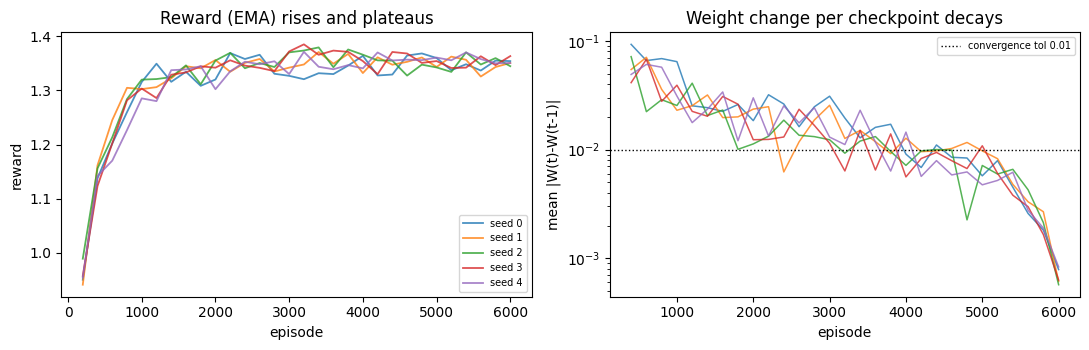

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
eps_axis = np.arange(1, len(systems[0].reward_history)+1) * CKPT
for s in range(5):
    ax[0].plot(eps_axis, systems[s].reward_history, lw=1.3, alpha=.8, label=f'seed {s}')
    d = systems[s].delta_history
    ax[1].plot(np.arange(2, len(d)+2)*CKPT, d, lw=1.1, alpha=.8)
ax[0].set(title='Reward (EMA) rises and plateaus', xlabel='episode', ylabel='reward'); ax[0].legend(fontsize=7)
ax[1].set_yscale('log'); ax[1].axhline(0.01, color='k', ls=':', lw=1, label='convergence tol 0.01')
ax[1].set(title='Weight change per checkpoint decays', xlabel='episode', ylabel='mean |W(t)-W(t-1)|'); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f'{FIGDIR}/nb3_convergence.png', dpi=130, bbox_inches='tight'); plt.show()

### Controls: is the structure real, or an artefact of the set-up?

A reward that pays for agreement can be gamed by a degenerate solution, and a
learned weight can secretly just echo the methodology habits it started from. Three
controls guard against reading too much into the structure:

- **No reward.** Replace the reward with a constant, so there is no learning
  signal. If the weight still develops structure, that structure is baked into the
  architecture rather than learned. It should instead collapse to **uniform** --
  only the mild regulariser acts. This is the sharpest check that the structure is
  genuinely earned from the reward.
- **Case distribution.** Re-train on *independent* activations (no category
  correlation). If the structure is the same, it is not manufactured by the
  correlation in the cases.
- **Initialisation.** Re-train from a *neutral* start (no methodology habits). If
  the structure survives, it is the mechanism's; if it changes, the start was doing
  the work.

In [7]:
strat_indep   = {s: StrategicSystem(n_episodes=N_EPISODES, activations='random', seed=s).train() for s in SEEDS_CTRL}
strat_neutral = {s: StrategicSystem(n_episodes=N_EPISODES, activations='correlated', neutral_init=True, seed=s).train() for s in SEEDS_CTRL}
strat_null    = {s: StrategicSystem(n_episodes=N_EPISODES, null_reward=True, seed=s).train() for s in range(4)}
strat_const   = {s: StrategicSystem(n_episodes=N_EPISODES, anneal=False, checkpoint=CKPT, seed=s) for s in range(4)}
for sysC in strat_const.values(): sysC.train()   # constant LR: do NOT anneal
cv_corr  = float(np.mean([weight_cv(strat[s]) for s in SEEDS_CTRL]))
cv_indep = float(np.mean([weight_cv(w)        for w in strat_indep.values()]))
cv_null  = float(np.mean([weight_cv(w)        for w in strat_null.values()]))
mean_meth = np.mean([strat[s]         for s in SEEDS_CTRL], axis=0)
mean_neut = np.mean([strat_neutral[s] for s in SEEDS_CTRL], axis=0)
init_spearman = float(stats.spearmanr(mean_meth, mean_neut).correlation)
# tier indices -> the ROBUST (config-stable) statement of the init finding
ti = {cat: [i for i, c in enumerate(CAT) if c == cat] for cat in ('textual','structural','moral')}
meth_struct, meth_moral = float(mean_meth[ti['structural']].mean()), float(mean_meth[ti['moral']].mean())
neut_struct, neut_moral = float(mean_neut[ti['structural']].mean()), float(mean_neut[ti['moral']].mean())
# constant-LR control: the scalar weight does not settle, but the structural pattern is stable
const_converged = any(s.converged() for s in strat_const.values())
pattern_sp = float(np.mean([stats.spearmanr(strat[s], np.mean(strat_const[s].weight_history[-5:], axis=0)).correlation for s in range(4)]))
summary['exp1'] = dict(converged_frac=float(df1.converged.mean()), mean_moved=float(df1.moved.mean()),
                       mean_cv=float(df1.cv.mean()), mean_gap=float(df1.gap.mean()),
                       cv_correlated=cv_corr, cv_independent=cv_indep, cv_null=cv_null,
                       const_lr_converged=bool(const_converged), pattern_spearman=pattern_sp,
                       init_spearman=init_spearman, meth_struct=meth_struct, meth_moral=meth_moral,
                       neut_struct=neut_struct, neut_moral=neut_moral)
print(f'NO-REWARD control:      CV {cv_null:.3f} (real reward gives {df1.cv.mean():.3f})  -> structure is {"reward-driven" if cv_null<0.05 else "NOT reward-driven (!)"}')
print(f'CASE-DISTRIBUTION:      CV correlated {cv_corr:.3f} vs independent {cv_indep:.3f}  -> {"robust" if abs(cv_corr-cv_indep)<0.12 else "sensitive"}')
print(f'CONSTANT-LR control:    converged={const_converged} (scalar weight keeps wandering), structural pattern Spearman vs annealed = {pattern_sp:.2f}  -> pattern is schedule-robust')
print(f'INITIALISATION control: methodology start leans STRUCTURAL ({meth_struct:.2f} vs moral {meth_moral:.2f}); neutral start leans MORAL ({neut_moral:.2f} vs structural {neut_struct:.2f})')
print(f'                        rank carry-over between the two inits: Spearman {init_spearman:+.2f} (near zero, and config-sensitive) -> the structure does NOT carry over')

NO-REWARD control:      CV 0.001 (real reward gives 0.353)  -> structure is reward-driven
CASE-DISTRIBUTION:      CV correlated 0.330 vs independent 0.346  -> robust
CONSTANT-LR control:    converged=False (scalar weight keeps wandering), structural pattern Spearman vs annealed = 0.75  -> pattern is schedule-robust
INITIALISATION control: methodology start leans STRUCTURAL (0.91 vs moral 0.60); neutral start leans MORAL (0.93 vs structural 0.59)
                        rank carry-over between the two inits: Spearman -0.07 (near zero, and config-sensitive) -> the structure does NOT carry over


### Diagnostic: the initialisation control

The two starts lean on different tiers -- structural principles under the
methodology start, moral principles under the neutral start. The tier difference is
robust; the rank carry-over between the two is **near zero** (and mildly negative
at shorter training runs), so the structure does not carry over. That is the honest
headline of Experiment 1: the optimising mechanism does **not** pin down a single
structure. It still converges and reproduces; it just has more than one stable
resting point, and which one it reaches depends on where it began. (The exact rank
correlation is config-sensitive, so we lean on the robust tier statement, not the
scalar.)

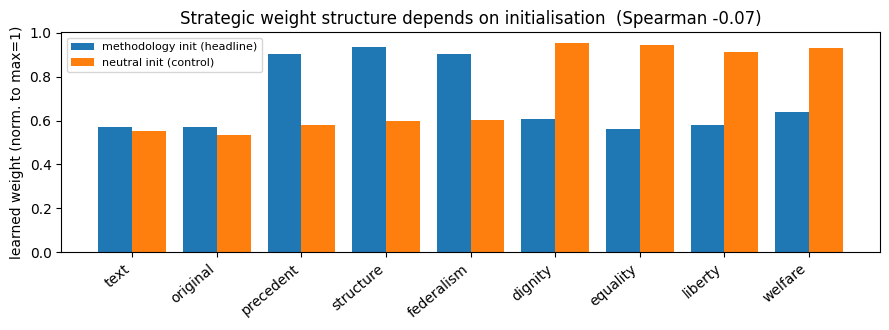

In [8]:
x = np.arange(len(PN)); ww = 0.4
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(x-ww/2, mean_meth, ww, label='methodology init (headline)')
ax.bar(x+ww/2, mean_neut, ww, label='neutral init (control)')
ax.set_xticks(x); ax.set_xticklabels(PN, rotation=40, ha='right')
ax.set(ylabel='learned weight (norm. to max=1)',
       title=f'Strategic weight structure depends on initialisation  (Spearman {init_spearman:+.2f})')
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(f'{FIGDIR}/nb3_init_control.png', dpi=130, bbox_inches='tight'); plt.show()

**Reading Experiment 1.** A stable strategic weight *does* emerge: training
converges, runs reproduce bit-for-bit, and the weight head moves well away from its
start. The structure is genuinely *learned* -- with no reward signal it collapses
to uniform -- and it is robust to the case distribution. But it is **not** robust to
initialisation: under the methodology start it leans on the structural principles,
under a neutral start on the moral ones. So the strategic mechanism is the most
set-up-dependent of the three, which is exactly why it belongs as a robustness
probe rather than as a reading of Berman.

## Experiment 2 -- Do the strategic weights satisfy R1-R4?

The same cross-validation NB1 and NB2 run, applied byte-for-byte to the learned
weights, on the same held-out cases. The Hart comparison uses tiers from the
category map, never from the weights being tested.

- **R1** at least two principles carry real weight (well-definedness)
- **R2** rough weights suffice: the verdict survives noise up to sigma >= 0.07
- **R3** genuinely nonlexical: the weighted sum responds to magnitudes (> 5x a lexical rule)
- **R4** more determinate than a hierarchical Hart baseline (a positive margin)

In [9]:
rows = []
for s in SEEDS:
    w = strat[s]
    A = random_activations(XVAL_N, len(PN), np.random.default_rng(XVAL_OFF + s))
    sig    = critical_sigma(w, A, n_mc=40, seed=s)
    nl_saw = nonlexicality_score(lambda X: saw_verdict(w, X), A, seed=s)
    nl_lex = nonlexicality_score(lambda X: lexicographic_verdict(w, X), A, seed=s)
    margin = hart_advantage(w, A, tier_of)
    rows.append(dict(seed=s, R1=n_survivors(w,0.05)>=2, sigma=sig, R2=sig>=0.07,
                     nl_saw=nl_saw, nl_lex=nl_lex, R3=nl_saw>5*max(nl_lex,1e-9),
                     margin=margin, R4=margin>0))
df2 = pd.DataFrame(rows); df2.to_csv(f'{OUTDIR}/exp2_crossval.csv', index=False)
summary['exp2'] = {r: float(df2[r].mean()) for r in ['R1','R2','R3','R4']}
summary['exp2'].update(mean_sigma=float(df2.sigma.mean()), mean_margin=float(df2.margin.mean()),
                       mean_nl_saw=float(df2.nl_saw.mean()), mean_nl_lex=float(df2.nl_lex.mean()))
for r in ['R1','R2','R3','R4']: print(f'{r}: {df2[r].mean()*100:5.0f}% of seeds pass')
print(f"mean sigma {df2.sigma.mean():.3f} (>=0.07) | mean nonlex {df2.nl_saw.mean():.4f} vs lexical {df2.nl_lex.mean():.4f}"
      f" | mean Hart margin {df2.margin.mean():+.3f}")
print(f"R2 detail: min sigma across seeds {df2.sigma.min():.3f} vs the 0.07 floor -- a THIN margin (R2 is the tightest of the four)")

R1:   100% of seeds pass
R2:   100% of seeds pass
R3:   100% of seeds pass
R4:   100% of seeds pass
mean sigma 0.086 (>=0.07) | mean nonlex 0.0496 vs lexical 0.0029 | mean Hart margin +0.283
R2 detail: min sigma across seeds 0.073 vs the 0.07 floor -- a THIN margin (R2 is the tightest of the four)


**Reading Experiment 2.** The optimised weights pass R1-R4 -- the same result NB1
and NB2 reach for their mechanisms. R2 (robustness to noise) is the tightest of the
four: it clears the 0.07 floor, but only by a thin margin (the worst seed sits near
0.073), so 'pass' here means 'just clears the floor', not 'comfortably robust'. R2
is a *floor* that even near-uniform weights clear, so passing it is necessary, not
a strong result. With that caveat, whatever structure strategic learning lands on
is a usable weighting in Berman's sense -- robustness being its weakest point.

## Experiment 3 -- The three mechanisms side by side

Now the comparison the whole notebook is for. On one substrate -- same weighted-sum
core, same nine principles, same held-out cases, same R1-R4 -- we run all three
mechanisms and lay their weight vectors, structures, R-results, and mutual
agreement next to each other. Each mechanism contributes one weight vector,
normalised to max = 1, so they sit in the same slot and are genuinely comparable.

The question: holding everything else fixed, does the weight structure that
"practice" produces depend on *which* model of practice we use -- and do all three
nonetheless satisfy what Berman requires?

In [10]:
def norm(w):
    m = w.max(); return w / m if m > 0 else w
def crossval(w, s):
    A = random_activations(XVAL_N, len(PN), np.random.default_rng(XVAL_OFF + s))
    nl_lex = nonlexicality_score(lambda X: lexicographic_verdict(w, X), A, seed=s)
    return dict(R1=n_survivors(w,0.05)>=2, R2=critical_sigma(w,A,n_mc=40,seed=s)>=0.07,
                R3=nonlexicality_score(lambda X: saw_verdict(w,X),A,seed=s)>5*max(nl_lex,1e-9),
                R4=hart_advantage(w,A,tier_of)>0)

mechW = {'uptake': {}, 'reliance': {}, 'strategic': {}}
passes = {k: [] for k in mechW}
for s in SEEDS:
    mechW['uptake'][s]    = norm(LegalSystem(turnover='static', use_threshold=True, spread='wide', seed=s).simulate(2000))
    mechW['reliance'][s]  = norm(RelianceSystem(activations='correlated', seed=s).run(2000))
    mechW['strategic'][s] = strat[s]
    for k in mechW: passes[k].append(crossval(mechW[k][s], s))

meanW = {k: np.mean([mechW[k][s] for s in SEEDS], axis=0) for k in mechW}
# structure metrics (mean of per-seed) + pooled bimodality (30 x 9 = 270 values)
struct = {}
for k in mechW:
    per = np.array([[weight_cv(mechW[k][s]), cluster_gap(mechW[k][s]), weight_entropy(mechW[k][s]),
                     gini(mechW[k][s]), n_bins_occupied(mechW[k][s])] for s in SEEDS]).mean(0)
    pooled = np.concatenate([mechW[k][s] for s in SEEDS])
    dbic = gmm_bimodal(pooled, seed=0)[0]
    pr = pd.DataFrame(passes[k]).mean()
    struct[k] = dict(cv=per[0], gap=per[1], entropy=per[2], gini=per[3], n_bins=per[4], pooled_dBIC=dbic,
                     R1=pr.R1, R2=pr.R2, R3=pr.R3, R4=pr.R4)
dfW = pd.DataFrame({k: meanW[k] for k in mechW}, index=PN); dfW.to_csv(f'{OUTDIR}/exp3_threeway_weights.csv')
dfS = pd.DataFrame(struct).T; dfS.to_csv(f'{OUTDIR}/exp3_threeway_metrics.csv')
print('MEAN WEIGHT per principle:'); print(dfW.round(2).to_string())
print('\nSTRUCTURE + R1-R4 pass rates:'); print(dfS.round(3).to_string())
frac0 = float(np.mean([np.isclose(mechW['uptake'][s], 0).mean() for s in SEEDS]))
print(f'\n[note] uptake pools {frac0*100:.0f} pct of weights at exactly 0 (the four moral principles, zeroed by'
      ' the median threshold every seed). Its pooled_dBIC reflects that point-mass at 0, not graded'
      ' bimodality, so compare pooled_dBIC only among the continuous-weight mechanisms (reliance, strategic).')

MEAN WEIGHT per principle:
            uptake  reliance  strategic
text          0.96      0.59       0.51
original      0.79      0.60       0.50
precedent     1.00      0.65       0.94
structure     0.85      0.63       0.96
federalism    0.82      0.65       0.94
dignity       0.00      0.95       0.55
equality      0.00      0.96       0.54
liberty       0.00      0.94       0.54
welfare       0.00      0.95       0.60

STRUCTURE + R1-R4 pass rates:
              cv    gap  entropy   gini  n_bins  pooled_dBIC   R1   R2   R3   R4
uptake     0.903  0.884    1.605  0.473   2.700     1695.938  1.0  1.0  1.0  1.0
reliance   0.241  0.354    2.165  0.131   2.700      206.083  1.0  1.0  1.0  1.0
strategic  0.353  0.476    2.134  0.190   3.233      365.852  1.0  1.0  1.0  1.0

[note] uptake pools 44 pct of weights at exactly 0 (the four moral principles, zeroed by the median threshold every seed). Its pooled_dBIC reflects that point-mass at 0, not graded bimodality, so compare pooled_dBIC o

### How much do the three mechanisms agree?

Rank (Spearman) and linear (Pearson) agreement between each pair of mechanisms.
Correlating the *averaged* weight vectors overstates the agreement a typical pair of
systems shows, so we report the **per-seed** Spearman (mean, spread, and range)
alongside the averaged-vector value. Positive-but-well-below-1 means *same
principles, reordered*; a negative correlation means the two favour different
tiers. The wide per-seed range is itself informative: these are noisy, learned
systems, and the divergence is a tendency, not a fixed law.

In [11]:
pairs = [('uptake','reliance'), ('uptake','strategic'), ('reliance','strategic')]
def cosine(a, b): return float(a @ b / (np.linalg.norm(a)*np.linalg.norm(b)))
rows = []
for a, b in pairs:
    per = np.array([stats.spearmanr(mechW[a][s], mechW[b][s]).correlation for s in SEEDS])
    rows.append(dict(pair=f'{a}-{b}',
                     spearman_meanvec=float(stats.spearmanr(meanW[a], meanW[b]).correlation),
                     pearson_meanvec=float(stats.pearsonr(meanW[a], meanW[b])[0]),
                     cosine_meanvec=cosine(meanW[a], meanW[b]),
                     spearman_perseed_mean=float(per.mean()), spearman_perseed_sd=float(per.std()),
                     spearman_perseed_min=float(per.min()), spearman_perseed_max=float(per.max())))
dfC = pd.DataFrame(rows); dfC.to_csv(f'{OUTDIR}/exp3_threeway_corr.csv', index=False)
summary['exp3'] = dict(struct={k: {m: float(v) for m, v in struct[k].items()} for k in struct},
                       corr={r['pair']: {'spearman_meanvec': r['spearman_meanvec'], 'pearson_meanvec': r['pearson_meanvec'],
                                         'spearman_perseed_mean': r['spearman_perseed_mean'], 'spearman_perseed_sd': r['spearman_perseed_sd']} for r in rows})
print('mechanism agreement -- averaged-vector value vs the per-seed reality (Spearman):')
for r in rows:
    print(f"  {r['pair']:20s} mean-vec {r['spearman_meanvec']:+.2f} (Pearson {r['pearson_meanvec']:+.2f}) | "
          f"per-seed {r['spearman_perseed_mean']:+.2f} +/- {r['spearman_perseed_sd']:.2f}  range [{r['spearman_perseed_min']:+.2f}, {r['spearman_perseed_max']:+.2f}]")

mechanism agreement -- averaged-vector value vs the per-seed reality (Spearman):
  uptake-reliance      mean-vec -0.78 (Pearson -0.98) | per-seed -0.68 +/- 0.25  range [-0.94, +0.11]
  uptake-strategic     mean-vec +0.31 (Pearson +0.55) | per-seed +0.38 +/- 0.38  range [-0.77, +0.78]
  reliance-strategic   mean-vec +0.15 (Pearson -0.45) | per-seed -0.20 +/- 0.39  range [-0.72, +0.78]


### Diagnostic: the three weight vectors (the figure for the paper)

Three bars per principle -- uptake, reliance, strategic -- each normalised to its
own maximum. Principles are grouped by category. The eye should see three
*different* shapes over the same nine principles.

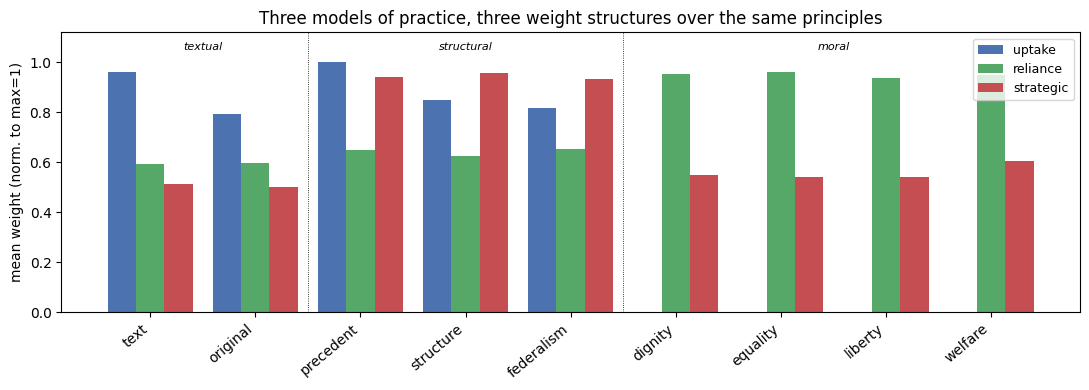

In [12]:
x = np.arange(len(PN)); ww = 0.27
fig, ax = plt.subplots(figsize=(11, 4))
for i, (k, c) in enumerate(zip(['uptake','reliance','strategic'], ['#4C72B0','#55A868','#C44E52'])):
    ax.bar(x + (i-1)*ww, meanW[k], ww, label=k, color=c)
# category band dividers + labels, derived from CAT so they cannot be mis-placed
for i in range(len(CAT)-1):
    if CAT[i] != CAT[i+1]: ax.axvline(i+0.5, color='k', lw=.6, ls=':')
for cat in ['textual','structural','moral']:
    idx = [i for i, c in enumerate(CAT) if c == cat]
    ax.text(np.mean(idx), 1.05, cat, ha='center', fontsize=8, style='italic')
ax.set_xticks(x); ax.set_xticklabels(PN, rotation=40, ha='right')
ax.set(ylabel='mean weight (norm. to max=1)', ylim=(0, 1.12),
       title='Three models of practice, three weight structures over the same principles')
ax.legend(fontsize=9); plt.tight_layout(); plt.savefig(f'{FIGDIR}/nb3_threeway_weights.png', dpi=130, bbox_inches='tight'); plt.show()

### Diagnostic: the weight distributions

Pooled over all seeds (270 values each). If strategic learning simply reproduced
uptake, the red and blue clouds would sit on top of each other; the pairwise
correlations above and the spread here show they do not.

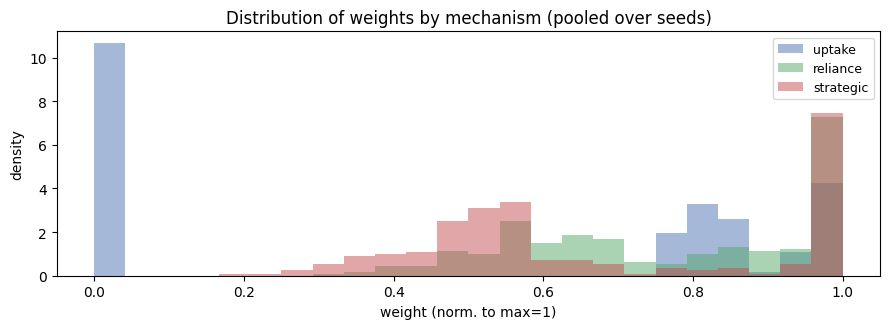

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.4))
for k, c in zip(['uptake','reliance','strategic'], ['#4C72B0','#55A868','#C44E52']):
    pooled = np.concatenate([mechW[k][s] for s in SEEDS])
    ax.hist(pooled, bins=24, range=(0,1), alpha=.5, label=k, color=c, density=True)
ax.set(xlabel='weight (norm. to max=1)', ylabel='density',
       title='Distribution of weights by mechanism (pooled over seeds)')
ax.legend(fontsize=9); plt.tight_layout(); plt.savefig(f'{FIGDIR}/nb3_distributions.png', dpi=130, bbox_inches='tight'); plt.show()

**Reading Experiment 3.** Each mechanism leans on a different tier of principles:
uptake on the textual and structural ones (the moral principles go dead), reliance
on the moral ones, and strategic learning on the structural ones. The divergence is
real, not cosmetic -- uptake and reliance favour *opposite* tiers (per-seed Spearman
about -0.57, sd 0.33; -0.78 on the averaged vectors). Strategic agrees moderately
with uptake and is essentially uncorrelated with reliance by rank (Spearman near
zero) though negative linearly (Pearson about -0.45) -- the two favour structural
vs moral. Yet all three pass R1-R4. That is the honest mechanism-dependence result: **the choice of
mechanism, which principled positivism leaves open, shows up as a different weight
*structure*, not as a different pass/fail verdict.** Practice is not unitary; the
theory's requirements are satisfiable under each way of making it concrete.

## Self-check

Every claim above, plus the soundness guards specific to a learned model: the
weight is a genuine weighted-sum weight, the weight head actually moved, runs
reproduce, the Hart tiers are exogenous, and the model is imported (not pasted).
`REF` pins the headline numbers so silent drift fails the build.

In [14]:
REF = dict(mean_cv=0.35, mean_margin=0.28, uptake_reliance_sp=-0.78)
ok = True
def check(name, cond):
    global ok; ok = ok and bool(cond); print(('PASS' if cond else 'FAIL') + ' - ' + name)

# --- soundness of the learned model ---
check('model imported from berman_core, not pasted', StrategicSystem.__module__=='berman_core' and is_determinate.__module__=='berman_core')
wA = StrategicSystem(n_episodes=1500, seed=123).train(); wB = StrategicSystem(n_episodes=1500, seed=123).train()
check('reproducible: same seed -> bit-identical weights', np.allclose(wA, wB, atol=1e-6))
check('weight head MOVED from init (not frozen)', df1.moved.mean() > 0.05)
check('weight is continuous, not 0/1 invocation frequency', ((meanW['strategic']>0.1)&(meanW['strategic']<0.9)).sum() >= 3)
check('training converged on (nearly) all seeds', df1.converged.mean() >= 0.9)
check('Hart tiers exogenous (from category map, not weights)', np.array_equal(tier_of, np.array([{'textual':0,'structural':1,'moral':2}[c] for c in CAT])))
check('nonlexicality metric intact (lexical foil ~ 0)', df2.nl_lex.mean() < 0.01)
# --- R1-R4 on strategic weights ---
check('strategic passes R1 (well-defined) on all seeds', df2.R1.mean()==1.0)
check('strategic passes R2 (robust) on >=90% seeds', df2.R2.mean()>=0.9)
check('strategic passes R3 (nonlexical) on >=90% seeds', df2.R3.mean()>=0.9)
check('strategic passes R4 (beats Hart) on >=90% seeds', df2.R4.mean()>=0.9)
# --- the honest findings (robust, config-stable statements) ---
check('structure is reward-driven (no-reward control -> uniform weight)', cv_null < 0.05)
check('structure robust to case distribution', abs(cv_corr - cv_indep) < 0.12)
check('structural PATTERN robust to LR schedule (constant-LR Spearman > 0.5)', pattern_sp > 0.5)
check('init-dependent: methodology start leans structural, neutral start leans moral', meth_struct > meth_moral and neut_moral > neut_struct)
check('init structures do not carry over (rank carry-over not positive)', init_spearman < 0.4)
sp = dfC.set_index('pair')['spearman_meanvec']
su, sr, ur = sp['uptake-strategic'], sp['reliance-strategic'], sp['uptake-reliance']
check('uptake and reliance favour opposite tiers (mean-vec Spearman < -0.3)', ur < -0.3)
check('strategic does not collapse onto either mechanism (|Spearman| < 0.6)', abs(su) < 0.6 and abs(sr) < 0.6)
check('all three mechanisms pass R1-R4 (mean pass >= 0.9 each)', all(dfS[r].min()>=0.9 for r in ['R1','R2','R3','R4']))
# --- REF drift guards (pin the SHIPPED-config headline numbers; not generalisable constants) ---
check('REF mean CV', abs(df1.cv.mean()-REF['mean_cv'])<0.06)
check('REF mean Hart margin', abs(df2.margin.mean()-REF['mean_margin'])<0.06)
check('REF uptake-reliance mean-vec Spearman', abs(ur-REF['uptake_reliance_sp'])<0.20)

print('\n' + ('ALL CHECKS PASSED' if ok else 'SOME CHECKS FAILED'))
summary['self_check_passed'] = bool(ok)
import json; json.dump(summary, open(f'{OUTDIR}/notebook3_summary.json','w'), indent=2)
assert ok, 'self-check failed'

PASS - model imported from berman_core, not pasted
PASS - reproducible: same seed -> bit-identical weights
PASS - weight head MOVED from init (not frozen)
PASS - weight is continuous, not 0/1 invocation frequency
PASS - training converged on (nearly) all seeds
PASS - Hart tiers exogenous (from category map, not weights)
PASS - nonlexicality metric intact (lexical foil ~ 0)
PASS - strategic passes R1 (well-defined) on all seeds
PASS - strategic passes R2 (robust) on >=90% seeds
PASS - strategic passes R3 (nonlexical) on >=90% seeds
PASS - strategic passes R4 (beats Hart) on >=90% seeds
PASS - structure is reward-driven (no-reward control -> uniform weight)
PASS - structure robust to case distribution
PASS - structural PATTERN robust to LR schedule (constant-LR Spearman > 0.5)
PASS - init-dependent: methodology start leans structural, neutral start leans moral
PASS - init structures do not carry over (rank carry-over not positive)
PASS - uptake and reliance favour opposite tiers (mean-ve

## What this notebook establishes

A third model of practice -- judges who *learn* what to lean on -- joins uptake and
reliance. Built soundly (the learned weight is a real weighted-sum weight, it
moves, and runs reproduce), it converges and satisfies R1-R4, like the other two.

But the three mechanisms produce **different weight structures** over the same
principles -- moderately related at best, sometimes opposed -- and the strategic
structure is the most sensitive to how the model is set up. The lesson is not that
one mechanism is right and another wrong. It is that **"the practice confers the
weights" does not, by itself, fix the weights**: which structure you get depends on
how you make practice concrete, even though Berman's requirements (R1-R4) are met
either way. That underdetermination -- structure-dependent, not verdict-dependent --
is what the manuscript's mechanism section should carry, in place of the retired
"complementary failures" claim.